In [1]:
%load_ext cuml.accel

In [2]:
from kids.catalog.preparation import load_and_prepare_inference_catalog
from kids.catalog.features import CLF_FEATURES

features = load_and_prepare_inference_catalog('../data/raw_data/KiDS_DR5_WCScut_columns_15MLN.csv').loc[:, CLF_FEATURES]

In [3]:
# features.describe(include='all')

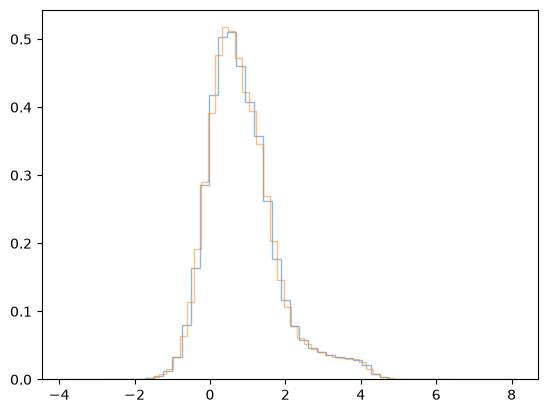

In [4]:
import matplotlib.pyplot as plt

plt.hist(features['u-r'], bins=50, alpha=0.5, density=True, histtype='step')
plt.hist(features['u-r'].sample(1_000_000), bins=50, alpha=0.5, density=True, histtype='step')
plt.show()

In [5]:
from sklearn.impute import SimpleImputer, KNNImputer

# imputer = SimpleImputer(strategy='median')
# imputer.fit(features.sample(1_000_000))

imputer = KNNImputer(n_neighbors=5, weights='uniform')
imputer.fit(features.sample(100_000))

,"missing_values missing_values: int, float, str, np.nan or None, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to np.nan, since `pd.NA` will be converted to np.nan.",nan
,"n_neighbors n_neighbors: int, default=5Number of neighboring samples to use for imputation.",5
,"weights weights: {'uniform', 'distance'} or callable, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- callable : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.",'uniform'
,"metric metric: {'nan_euclidean'} or callable, default='nan_euclidean'Distance metric for searching neighbors. Possible values:- 'nan_euclidean'- callable : a user-defined function which conforms to the definition of ``func_metric(x, y, *, missing_values=np.nan)``. `x` and `y` corresponds to a row (i.e. 1-D arrays) of `X` and `Y`, respectively. The callable should returns a scalar distance value.",'nan_euclidean'
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto theoutput of the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear on themissing indicator even if there are missing values at transform/testtime.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0`... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](91,)","['u-g','u-r','u-i1',...,'J/Ks','H/Ks','CLASS_STAR']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.``None`` if add_indicator is False.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,91


In [ ]:
# 2 min 57 seconds for 10_000 samples on cpu only
# 2 min 46 secodsn for 10_000 samples with cuml.accel
transformed_features = imputer.transform(features.sample(10_000))

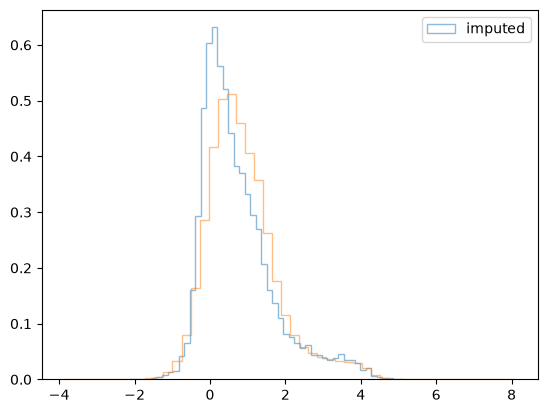

In [ ]:
plt.hist(transformed_features[:, CLF_FEATURES.index('u-r')], bins=50, alpha=0.5, histtype='step', density=True, label='imputed')
plt.hist(features['u-r'], bins=50, alpha=0.5, histtype='step', density=True)
plt.legend()
plt.show()